# NN Pruning — multi-dataset generalization

Extension of `NNpruning_experiment_1.ipynb` to **multiple UCI datasets** (Iris, Wine, Cancer).

Hypothesis: EvoluPrune should outperform magnitude pruning **consistently across datasets**, not just Cancer. A robust cross-domain win supports the NeurIPS narrative that evolutionary parsimony generalises without per-domain tuning.

Key differences from experiment 1:
1. Loop over `{iris, wine, cancer}` — runs full pipeline per dataset
2. `MaskedMLP` and helpers use `dims=None` with runtime lookup of global `DIMS` (so redefinition between datasets works)
3. Results aggregated in nested dict `{dataset: {method: results}}`
4. Final multi-dataset comparison table

## Imports

In [1]:
import json, os, warnings, random, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from joblib import Parallel, delayed
from sklearn.datasets import load_wine, load_iris, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pickle

def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

## Config

In [2]:
DATASETS  = ["iris", "wine", "cancer"]
HIDDEN    = [64, 32]
ALPHA     = 500.0
F_TARGET  = 0.05
DEVICE    = "cpu"
INNER_EPOCHS = 80
INNER_LR     = 0.01
SEEDS = [0, 1, 2, 3, 4]
N_EPOCH_MULTI = 60
POP_MULTI = 30
RESULTS_FILE = "nnpruning2_results.pkl"

X_tr = y_tr = X_te = y_te = None
IN_DIM = OUT_DIM = None
DIMS = None

## Data

In [3]:
def load_dataset(name):
    if name == "iris":
        d = load_iris()
    elif name == "wine":
        d = load_wine()
    elif name == "cancer":
        d = load_breast_cancer()
    else:
        raise ValueError(name)
    X, y = d.data, d.target
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
    sc = StandardScaler().fit(X_tr)
    X_tr = torch.tensor(sc.transform(X_tr), dtype=torch.float32)
    X_te = torch.tensor(sc.transform(X_te), dtype=torch.float32)
    y_tr = torch.tensor(y_tr, dtype=torch.long)
    y_te = torch.tensor(y_te, dtype=torch.long)
    return X_tr, y_tr, X_te, y_te, int(X_tr.shape[1]), int(len(set(d.target.tolist())))

def activate_dataset(name):
    global X_tr, y_tr, X_te, y_te, IN_DIM, OUT_DIM, DIMS
    X_tr, y_tr, X_te, y_te, IN_DIM, OUT_DIM = load_dataset(name)
    DIMS = [IN_DIM] + HIDDEN + [OUT_DIM]
    print(f"{name}: in={IN_DIM}, out={OUT_DIM}, train={len(X_tr)}, test={len(X_te)}, dims={DIMS}")

## MaskedMLP

In [4]:
class MaskedMLP(nn.Module):
    def __init__(self, dims=None):
        super().__init__()
        if dims is None:
            dims = DIMS
        self.dims = list(dims)
        self.layers = nn.ModuleList([nn.Linear(self.dims[i], self.dims[i+1]) for i in range(len(self.dims)-1)])
        self.masks = nn.ParameterList([
            nn.Parameter(torch.ones_like(l.weight), requires_grad=False)
            for l in self.layers
        ])

    def forward(self, x):
        for i, l in enumerate(self.layers):
            w = l.weight * self.masks[i]
            x = F.linear(x, w, l.bias)
            if i < len(self.layers) - 1:
                x = F.relu(x)
        return x

    def density(self):
        total = sum(m.numel() for m in self.masks)
        active = sum(float(m.sum().item()) for m in self.masks)
        return active / total

    def clone_arch(self):
        new = MaskedMLP(self.dims)
        for i, l in enumerate(self.layers):
            new.layers[i].weight.data.copy_(l.weight.data)
            new.layers[i].bias.data.copy_(l.bias.data)
            new.masks[i].data.copy_(self.masks[i].data)
        return new

## Topology mutations

In [5]:
def random_modif(model, n_flips=None, f_target=None):
    model = model.clone_arch()
    total = sum(m.numel() for m in model.masks)
    if n_flips is None:
        n_flips = max(1, int(0.02 * total))
    if f_target is not None:
        current_d = model.density()
        p_add = float(np.clip(0.5 - 4.0 * (current_d - f_target), 0.05, 0.95))
    else:
        p_add = 0.5
    for _ in range(n_flips):
        li = np.random.randint(len(model.masks))
        m = model.masks[li]
        if np.random.random() < p_add:
            inactive = torch.where(m.data.flatten() < 0.5)[0]
            if len(inactive) == 0:
                continue
            flat = int(inactive[np.random.randint(len(inactive))].item())
        else:
            active = torch.where(m.data.flatten() > 0.5)[0]
            if len(active) == 0:
                continue
            flat = int(active[np.random.randint(len(active))].item())
        idx = np.unravel_index(flat, m.shape)
        m.data[idx] = 1.0 - m.data[idx]
    return model

def random_ini(density=0.3, dims=None):
    if dims is None:
        dims = DIMS
    model = MaskedMLP(dims)
    for i in range(len(model.masks)):
        model.masks[i].data = (torch.rand_like(model.masks[i]) < density).float()
    return model

## Fitness

In [6]:
class EvalCounter:
    def __init__(self): self.n = 0
    def reset(self): self.n = 0

EVAL = EvalCounter()

def train_inner_adam(model, X, y, epochs=INNER_EPOCHS, lr=INNER_LR):
    opt = torch.optim.Adam([p for l in model.layers for p in (l.weight, l.bias)], lr=lr)
    for _ in range(epochs):
        opt.zero_grad()
        loss = F.cross_entropy(model(X), y)
        loss.backward()
        with torch.no_grad():
            for i, l in enumerate(model.layers):
                if l.weight.grad is not None:
                    l.weight.grad.mul_(model.masks[i])
        opt.step()
        with torch.no_grad():
            for i, l in enumerate(model.layers):
                l.weight.data.mul_(model.masks[i])
    return model

def eval_accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        pred = model(X).argmax(dim=1)
        return float((pred == y).float().mean().item())

def score(model, f_target, alpha=ALPHA):
    EVAL.n += 1
    model = train_inner_adam(model, X_tr, y_tr)
    acc_tr = eval_accuracy(model, X_tr, y_tr)
    acc_te = eval_accuracy(model, X_te, y_te)
    density = model.density()
    s = acc_te - alpha * (density - f_target) ** 2
    if np.isnan(s):
        s = -1e6
    return s, acc_tr, acc_te, density, model

## Evolutive train

In [7]:
def run_inner_eval(model, f_target):
    warnings.filterwarnings("ignore", category=UserWarning)
    try:
        s, acc_tr, acc_te, density, trained = score(model, f_target)
        return s, acc_tr, acc_te, density, trained
    except Exception as e:
        print(f"eval failed: {e}")
        return -1e6, 0.0, 0.0, 1.0, model

def train_evolutive(init_pop, n_epoch, f_target,
                    n_jobs=-1, elitism=5, reseed=10, verbose=False,
                    min_epoch=20, patience=10, tol=1e-4):
    history = {k: {"acc_tr": [], "acc_te": [], "density": [], "loss": []}
               for k in ("best", "second", "third", "mid")}
    avg_density = []
    pop_size = len(init_pop)
    circuit_list = init_pop
    for epoch in range(n_epoch):
        evaluated = Parallel(n_jobs=n_jobs)(
            delayed(run_inner_eval)(m, f_target) for m in circuit_list)
        scored = []
        for i, (s, atr, ate, d, trained) in enumerate(evaluated):
            scored.append((s, i, atr, ate, d))
            circuit_list[i] = trained
        scored.sort(reverse=True)
        for key, rank in (("best", 0), ("second", 1), ("third", 2),
                          ("mid", len(scored) // 2)):
            history[key]["acc_tr"].append(scored[rank][2])
            history[key]["acc_te"].append(scored[rank][3])
            history[key]["density"].append(scored[rank][4])
            history[key]["loss"].append(-scored[rank][0])

        max_s = scored[0][0]
        lo, hi = elitism, pop_size - reseed
        weights = np.array([max_s - t[0] + 1e-6 for t in scored[lo:hi]])
        probs = weights / weights.sum()
        picks = set(np.random.choice(range(lo, hi), size=reseed,
                                     replace=False, p=probs).tolist())
        for i in range(1, reseed + 1):
            circuit_list[scored[-i][1]] = random_ini(density=f_target)

        parent_ranks = [k // 2 for k in range(reseed)]
        assert parent_ranks[-1] < elitism
        for pr, i in zip(parent_ranks, sorted(picks)):
            parent = circuit_list[scored[pr][1]]
            circuit_list[scored[i][1]] = random_modif(parent, f_target=f_target)
        for i in range(lo, hi):
            if i not in picks:
                circuit_list[scored[i][1]] = random_modif(circuit_list[scored[i][1]], f_target=f_target)

        avg_density.append(float(np.mean([m.density() for m in circuit_list])))
        if verbose:
            print(f"epoch {epoch:3d}  acc_te={scored[0][3]:.4f}  "
                  f"density={scored[0][4]:.3f}  avg_d={avg_density[-1]:.3f}")

        if epoch + 1 >= min_epoch:
            recent = history["best"]["loss"][-patience:]
            if len(recent) == patience and (max(recent) - min(recent)) < tol:
                if verbose:
                    print(f"early stop at epoch {epoch}")
                break

    best_model = circuit_list[scored[0][1]]
    return best_model, circuit_list, avg_density, history

## Baselines

In [8]:
def train_dense(dims=None, epochs=200, lr=0.01, seed=0):
    if dims is None:
        dims = DIMS
    set_all_seeds(seed)
    model = MaskedMLP(dims)
    train_inner_adam(model, X_tr, y_tr, epochs=epochs, lr=lr)
    return model

def magnitude_pruning(dims=None, target_density=0.3, epochs=200, lr=0.01, seed=0):
    if dims is None:
        dims = DIMS
    model = train_dense(dims, epochs=epochs, lr=lr, seed=seed)
    all_w = torch.cat([l.weight.abs().flatten() for l in model.layers])
    k = int(target_density * all_w.numel())
    if k == 0:
        thresh = float(all_w.max().item()) + 1.0
    else:
        thresh = float(torch.topk(all_w, k).values[-1].item())
    for i, l in enumerate(model.layers):
        model.masks[i].data = (l.weight.abs() >= thresh).float()
    train_inner_adam(model, X_tr, y_tr, epochs=epochs, lr=lr)
    return model

def random_pruning(dims=None, target_density=0.3, epochs=200, lr=0.01, seed=0):
    if dims is None:
        dims = DIMS
    set_all_seeds(seed)
    model = MaskedMLP(dims)
    for i in range(len(model.masks)):
        model.masks[i].data = (torch.rand_like(model.masks[i]) < target_density).float()
    train_inner_adam(model, X_tr, y_tr, epochs=epochs, lr=lr)
    return model

def snip_pruning(dims=None, target_density=0.3, epochs=200, lr=0.01, seed=0):
    if dims is None:
        dims = DIMS
    set_all_seeds(seed)
    model = MaskedMLP(dims)
    for l in model.layers:
        l.weight.requires_grad_(True)
    out = model(X_tr)
    loss = F.cross_entropy(out, y_tr)
    grads = torch.autograd.grad(loss, [l.weight for l in model.layers])
    saliencies = torch.cat([torch.abs(l.weight * g).flatten() for l, g in zip(model.layers, grads)])
    k = int(target_density * saliencies.numel())
    thresh = float(torch.topk(saliencies, k).values[-1].item()) if k > 0 else float("inf")
    for i, l in enumerate(model.layers):
        model.masks[i].data = (torch.abs(l.weight * grads[i]) >= thresh).float()
    train_inner_adam(model, X_tr, y_tr, epochs=epochs, lr=lr)
    return model

def synflow_pruning(dims=None, target_density=0.3, epochs=200, lr=0.01, seed=0, n_iter=100):
    if dims is None:
        dims = DIMS
    set_all_seeds(seed)
    model = MaskedMLP(dims)
    with torch.no_grad():
        weights_backup = [l.weight.data.clone() for l in model.layers]
        bias_backup = [l.bias.data.clone() for l in model.layers]
        for l in model.layers:
            l.weight.data = l.weight.data.abs()
            l.bias.data = l.bias.data.abs()
    input_ones = torch.ones(1, dims[0])
    end_sparsity = 1.0 - target_density
    for it in range(n_iter):
        out = model(input_ones)
        loss = out.sum()
        grads = torch.autograd.grad(loss, [l.weight for l in model.layers])
        saliencies = torch.cat([torch.abs(l.weight * g * m).flatten()
                                for l, g, m in zip(model.layers, grads, model.masks)])
        sparsity = end_sparsity * ((it + 1) / n_iter) ** 3
        keep = int((1 - sparsity) * saliencies.numel())
        if keep > 0:
            thresh = float(torch.topk(saliencies, keep).values[-1].item())
            for i, l in enumerate(model.layers):
                w_sal = torch.abs(l.weight * grads[i] * model.masks[i])
                model.masks[i].data = (w_sal >= thresh).float()
    with torch.no_grad():
        for l, w, b in zip(model.layers, weights_backup, bias_backup):
            l.weight.data = w
            l.bias.data = b
    train_inner_adam(model, X_tr, y_tr, epochs=epochs, lr=lr)
    return model

def imp_pruning(dims=None, target_density=0.3, epochs=100, lr=0.01, seed=0, n_rounds=5):
    if dims is None:
        dims = DIMS
    set_all_seeds(seed)
    model = MaskedMLP(dims)
    train_inner_adam(model, X_tr, y_tr, epochs=epochs, lr=lr)
    for r in range(1, n_rounds + 1):
        target_r = 1.0 - (1.0 - target_density) * (r / n_rounds)
        all_w = torch.cat([l.weight.abs().flatten() for l in model.layers])
        k = int(target_r * all_w.numel())
        thresh = float(torch.topk(all_w, k).values[-1].item()) if k > 0 else float("inf")
        for i, l in enumerate(model.layers):
            model.masks[i].data = (l.weight.abs() >= thresh).float()
        train_inner_adam(model, X_tr, y_tr, epochs=epochs, lr=lr)
    return model

BASELINES = {
    "Magnitude": magnitude_pruning,
    "IMP":       imp_pruning,
    "SNIP":      snip_pruning,
    "SynFlow":   synflow_pruning,
    "Random":    random_pruning,
}

## Helpers

In [9]:
def _run_evolutive(seed, f_target):
    set_all_seeds(seed)
    init_pop = [random_ini(density=f_target) for _ in range(POP_MULTI)]
    return train_evolutive(init_pop, n_epoch=N_EPOCH_MULTI, f_target=f_target,
                           elitism=5, reseed=10, verbose=False)

def _run_baseline(fn, seed, target_density):
    m = fn(target_density=target_density, seed=seed)
    acc = eval_accuracy(m, X_te, y_te)
    density = m.density()
    return m, acc, density

def build_fake_history(acc, density, f_target, n_epoch=N_EPOCH_MULTI):
    h = {k: {"acc_tr": [], "acc_te": [], "density": [], "loss": []}
         for k in ("best", "second", "third", "mid")}
    for k in h:
        h[k]["acc_te"] = [acc] * n_epoch
        h[k]["acc_tr"] = [acc] * n_epoch
        h[k]["density"] = [density] * n_epoch
        h[k]["loss"] = [-(acc - ALPHA * (density - f_target) ** 2)] * n_epoch
    return h

def run_all_for_dataset(name, f_target=F_TARGET, seeds=SEEDS):
    activate_dataset(name)
    results = {}
    best_l, pop_l, avg_l, hist_l, eval_l = [], [], [], [], []
    for s in seeds:
        print(f"[{name}] EvoluPrune seed={s}")
        EVAL.reset()
        b, p, a, h = _run_evolutive(s, f_target)
        best_l.append(b); pop_l.append(p); avg_l.append(a); hist_l.append(h); eval_l.append(EVAL.n)
    results["EvoluPrune"] = (best_l, pop_l, avg_l, hist_l, eval_l)

    for bn, bfn in BASELINES.items():
        bl, hl, el = [], [], []
        for s in seeds:
            print(f"[{name}] {bn} seed={s}")
            m, acc, dens = _run_baseline(bfn, s, f_target)
            bl.append(m); hl.append(build_fake_history(acc, dens, f_target)); el.append(200)
        results[bn] = (bl, [None] * len(seeds), [None] * len(seeds), hl, el)

    return results

## Driver — loop over datasets

In [10]:
all_results = {}
for ds in DATASETS:
    all_results[ds] = run_all_for_dataset(ds)
    with open(RESULTS_FILE, "wb") as f:
        pickle.dump(all_results, f)
    print(f"=== saved {ds} ===\n")

iris: in=4, out=3, train=105, test=45, dims=[4, 64, 32, 3]
[iris] EvoluPrune seed=0
[iris] EvoluPrune seed=1
[iris] EvoluPrune seed=2
[iris] EvoluPrune seed=3
[iris] EvoluPrune seed=4
[iris] Magnitude seed=0
[iris] Magnitude seed=1
[iris] Magnitude seed=2
[iris] Magnitude seed=3
[iris] Magnitude seed=4
[iris] IMP seed=0
[iris] IMP seed=1
[iris] IMP seed=2
[iris] IMP seed=3
[iris] IMP seed=4
[iris] SNIP seed=0
[iris] SNIP seed=1
[iris] SNIP seed=2
[iris] SNIP seed=3
[iris] SNIP seed=4
[iris] SynFlow seed=0
[iris] SynFlow seed=1
[iris] SynFlow seed=2
[iris] SynFlow seed=3
[iris] SynFlow seed=4
[iris] Random seed=0
[iris] Random seed=1
[iris] Random seed=2
[iris] Random seed=3
[iris] Random seed=4
=== saved iris ===

wine: in=13, out=3, train=124, test=54, dims=[13, 64, 32, 3]
[wine] EvoluPrune seed=0
[wine] EvoluPrune seed=1
[wine] EvoluPrune seed=2
[wine] EvoluPrune seed=3
[wine] EvoluPrune seed=4
[wine] Magnitude seed=0
[wine] Magnitude seed=1
[wine] Magnitude seed=2
[wine] Magnitude s

## Aggregate results

In [11]:
def aggregate_table(all_results, f_target=F_TARGET):
    rows = []
    for ds, methods in all_results.items():
        for method, res in methods.items():
            best_list, _, _, history_list, toteval_list = res
            acc = np.array([h["best"]["acc_te"][-1] for h in history_list])
            dens = np.array([h["best"]["density"][-1] for h in history_list])
            loss = np.array([h["best"]["loss"][-1] for h in history_list])
            rows.append({
                "Dataset":  ds,
                "Method":   method,
                "Test acc": f"{acc.mean():.3f} ± {acc.std():.3f}",
                "Density":  f"{dens.mean():.3f} ± {dens.std():.3f}",
                "Loss":     f"{loss.mean():.3f} ± {loss.std():.3f}",
            })
    return pd.DataFrame(rows)

aggregate_table(all_results)

,Dataset,Method,Test acc,Density,Loss
0,iris,EvoluPrune,0.933 ± 0.000,0.050 ± 0.000,-0.933 ± 0.000
1,iris,Magnitude,0.938 ± 0.022,0.050 ± 0.000,-0.938 ± 0.022
2,iris,IMP,0.911 ± 0.020,0.050 ± 0.000,-0.911 ± 0.020
3,iris,SNIP,0.920 ± 0.011,0.050 ± 0.000,-0.920 ± 0.011
4,iris,SynFlow,0.902 ± 0.011,0.050 ± 0.000,-0.902 ± 0.011
5,iris,Random,0.449 ± 0.231,0.053 ± 0.004,-0.437 ± 0.212
6,wine,EvoluPrune,0.996 ± 0.007,0.052 ± 0.003,-0.991 ± 0.007
7,wine,Magnitude,0.411 ± 0.044,0.050 ± 0.000,-0.411 ± 0.044
8,wine,IMP,0.885 ± 0.095,0.050 ± 0.000,-0.885 ± 0.095
9,wine,SNIP,0.959 ± 0.032,0.050 ± 0.000,-0.959 ± 0.032


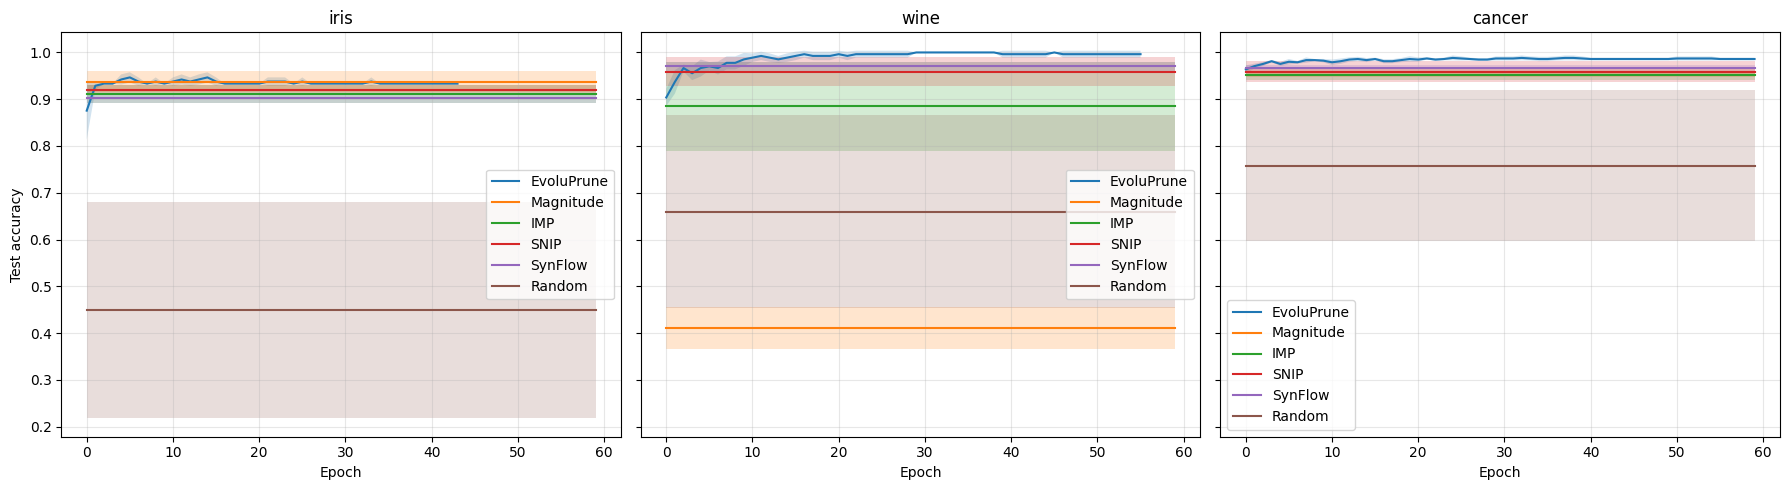

In [14]:
def _pad_right(arr, target_len):
    if len(arr) >= target_len:
        return arr[:target_len]
    return list(arr) + [arr[-1]] * (target_len - len(arr))

fig, axes = plt.subplots(1, len(DATASETS), figsize=(6 * len(DATASETS), 5), sharey=True)
if len(DATASETS) == 1:
    axes = [axes]
for ax, ds in zip(axes, DATASETS):
    methods = all_results[ds]
    for method, res in methods.items():
        history_list = res[3]
        max_len = max(len(h["best"]["acc_te"]) for h in history_list)
        acc = np.array([_pad_right(h["best"]["acc_te"], max_len) for h in history_list])
        mean = acc.mean(axis=0); std = acc.std(axis=0)
        eps = np.arange(max_len)
        ax.plot(eps, mean, label=method)
        ax.fill_between(eps, mean - std, mean + std, alpha=0.2)
    ax.set_xlabel("Epoch"); ax.set_title(ds)
    ax.legend(); ax.grid(alpha=0.3)
axes[0].set_ylabel("Test accuracy")
plt.tight_layout(); plt.show()
